# 4. Explanations

`fico_xml.explain.explain` takes the raw record of an applicant through the
whole pipeline and explains the decision with two kinds of counterfactual
statements (computed by [CtreeX][ctreex]):

* the **class-contrastive** ones communicated the smallest changes that would
  reverse the decision; and
* the **class-equivalent** ones communicate changes that would *not* alter it,
  which show how much room there is.

Statements that change fewer features come first;
among those, the ones that use features shared by more leaves of the tree come
first.

[ctreex]: https://github.com/So-Cool/ctreex

In [1]:
import warnings
warnings.filterwarnings('ignore')
from fico_xml import data, model, preprocessing
from fico_xml.explain import explain

raw = data.load_raw()
tree = model.train(preprocessing.clean(raw))

## A declined application

In [2]:
first = explain(tree, raw.loc[34])
first.values

{'NumTotalTrades': 26,
 'NumSatisfactoryTrades': 23,
 'NumTrades60Ever2DerogPubRec': 2,
 'NumTrades90Ever2DerogPubRec': 2,
 'NumTradesOpeninLast12M': 5,
 'NumRevolvingTradesWBalance': 5,
 'NumInstallTradesWBalance': 3,
 'NumBank2NatlTradesWHighUtilization': 1,
 'NumInqLast6Mexcl7days': 0,
 'NumInqLast7DCalc': 0}

In [3]:
print(first.text(limit=3))

The application is declined.
The application would be accepted had there been no credit accounts that were ever 60 or more days overdue or have a derogatory public record (instead of 2).
The application would be accepted had there been no bank or national credit-card accounts with high utilisation (instead of 1) and the number of credit accounts that were ever 60 or more days overdue or have a derogatory public record been exactly 1 (instead of 2).
The application would be accepted had the total number of credit accounts been at least 27 (instead of 26) and there been no credit accounts that were ever 60 or more days overdue or have a derogatory public record (instead of 2).
The application would still be declined had the number of credit accounts in good standing been at most 19 or at least 33 (instead of 23).
The application would still be declined had the number of bank or national credit-card accounts with high utilisation been at most 0 or at least 3 (instead of 1).
The applicatio

A single change suffices:
no account 60 or more days overdue.
Other paths to acceptance need two or more changes.
The class-equivalent statements show, for example, that the number of accounts
in good standing could change considerably without affecting the decision.

## An inconsistent record

This applicant's record contradicts itself, so it is not assessed;
the applicant is told what to correct:

In [4]:
print(explain(tree, raw.loc[678]).text())

Your worst payment delay in the last 12 months is worse than your worst payment delay ever. Your worst payment delay ever is shorter than 60 days, but some of your accounts were 60 or more days overdue. Your worst payment delay ever is shorter than 90 days, but some of your accounts were 90 or more days overdue. The record has to be corrected before it can be assessed.


## An accepted application

In [5]:
third = explain(tree, raw.loc[7890])
print(third.text(limit=4))

The application is accepted.
The application would be declined had the number of bank or national credit-card accounts with high utilisation been at least 2 (instead of 0).
The application would be declined had the number of credit accounts in good standing been at most 10 (instead of 20).
The application would be declined had the number of credit accounts opened in the last 12 months been at least 4 (instead of 3).
The application would be declined had the number of credit accounts that were ever 60 or more days overdue or have a derogatory public record been at least 2 (instead of 0).
The application would still be accepted had the number of credit accounts opened in the last 12 months been at most 2 (instead of 3).
The application would still be accepted had the number of credit accounts in good standing been at least 27 (instead of 20).
The application would still be accepted had the number of credit accounts that were ever 60 or more days overdue or have a derogatory public record

This applicant did not, in fact, repay as agreed (`Bad`) and the explanation
shows how close the decision was:
one more account opened in the last 12 months or two highly utilised credit
cards would have reversed it.

## Monotonicity

The data dictionary states how every feature should affect the risk;
for example, more credit checks or more accounts 60 days overdue should never
make an application *more* likely to be accepted.
**The decision tree does not obey these constraints**:
many counterfactuals move a feature in the opposite direction
(e.g., "the application would be accepted had *more* accounts been opened in
the last 12 months").
`explain` flags such counterfactuals, notes them in the text and issues a
warning:

In [6]:
import warnings
from fico_xml.explain import MonotonicityWarning

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', MonotonicityWarning)
    explanation = explain(tree, raw.loc[2])
print(*[str(w.message) for w in caught], sep='\n')
print(explanation.text(limit=4))

3 of the 16 class-contrastive counterfactuals move a feature against its monotonicity constraint (the model does not obey the constraints of the data dictionary).
The application is declined.
The application would be accepted had there been no bank or national credit-card accounts with high utilisation (instead of 1) and the number of credit accounts in good standing been at least 27 (instead of 9).
The application would be accepted had there been no bank or national credit-card accounts with high utilisation (instead of 1) and the number of credit accounts opened in the last 12 months been at most 1 (instead of 4).
The application would be accepted had the number of credit checks in the last 6 months (excluding the last 7 days) been at most 3 (instead of 4) and the number of credit accounts in good standing been at least 20 (instead of 9).
The application would be accepted had there been no bank or national credit-card accounts with high utilisation (instead of 1) and the number of cr

How common this is for the applicants the model can explain
(the share of class-contrastive counterfactuals that contradict the constraints
for a random sample of 300):

In [7]:
import pandas as pd

X, y = model.model_data(preprocessing.clean(raw))
sample = X.sample(300, random_state=0).index
explanations = {i: explain(tree, raw.loc[i], warn=False) for i in sample}
counterfactuals = [cf for e in explanations.values() for cf in e.contrastive]
pd.Series({
    'counterfactuals': len(counterfactuals),
    'contradicting monotonicity': sum(bool(cf.contradicts_monotonicity) for cf in counterfactuals),
    'applicants whose best counterfactual contradicts it': sum(
        bool(e.contrastive and e.contrastive[0].contradicts_monotonicity) for e in explanations.values())})

counterfactuals                                        5852
contradicting monotonicity                             2451
applicants whose best counterfactual contradicts it       5
dtype: int64

Notebook 5 trains a decision tree that respects the constraints.

## Consistent counterfactuals

Counterfactuals change a few features and keep the others, which can produce a
record that contradicts itself, e.g., fewer accounts 60 days overdue than 90
days overdue.
Every counterfactual records whether its *closest* change gives
a consistent record;
`consistent_only=True` keeps only those.
For the declined applicant above, every class-contrastive counterfactual
lowers the number of accounts 60 days overdue below the number of accounts 90
days overdue, so none is consistent:

In [8]:
first_consistent = explain(tree, raw.loc[34], consistent_only=True, warn=False)
print(first_consistent.text(limit=2))

The application is declined.
No change of the record would make the application accepted.
The application would still be declined had the number of credit accounts in good standing been at most 19 or at least 33 (instead of 23).
The application would still be declined had the number of bank or national credit-card accounts with high utilisation been at most 0 or at least 3 (instead of 1).


In [9]:
pd.Series({'counterfactuals': len(counterfactuals),
           'consistent': sum(cf.consistent for cf in counterfactuals)})

counterfactuals    5852
consistent         3395
dtype: int64

## Actionable counterfactuals

Many counterfactuals ask to change the past ("had no account ever been 60 days
overdue").
`actionable_only=True` restricts the class-contrastive counterfactuals to what
an applicant can do;
this includes paying off balances (fewer accounts with a balance or with high
utilisation) and applying for or opening less credit
(fewer credit checks and new accounts):

In [10]:
model.ACTIONABLE

{'NumRevolvingTradesWBalance': 'decrease',
 'NumInstallTradesWBalance': 'decrease',
 'NumBank2NatlTradesWHighUtilization': 'decrease',
 'NumInqLast6Mexcl7days': 'decrease',
 'NumInqLast7DCalc': 'decrease',
 'NumTradesOpeninLast12M': 'decrease'}

In [11]:
advice = explain(tree, raw.loc[2], actionable_only=True, consistent_only=True, warn=False)
print(advice.text(limit=3))

The application is declined.
The application would be accepted had there been no bank or national credit-card accounts with high utilisation (instead of 1) and the number of credit accounts opened in the last 12 months been at most 1 (instead of 4).
The application would still be declined had there been no bank or national credit-card accounts with high utilisation (instead of 1).
The application would still be declined had the number of credit checks in the last 6 months (excluding the last 7 days) been at most 1 (instead of 4).
The application would still be declined had the number of revolving accounts (credit cards, credit lines) with a balance been at least 6 (instead of 4).


Some declined applicants can do nothing within the model;
for example, the first applicant, whose decision depends on past delinquency:

In [12]:
print(explain(tree, raw.loc[34], actionable_only=True, warn=False).text(limit=0))

The application is declined.
No possible change of the record would make the application accepted.


In [13]:
declined = [i for i, e in explanations.items() if e.prediction == 'Bad']
with_advice = sum(bool(explain(tree, raw.loc[i], actionable_only=True, consistent_only=True,
                               warn=False).contrastive) for i in declined)
pd.Series({'declined (sample)': len(declined), 'with consistent, actionable advice': with_advice})

declined (sample)                     163
with consistent, actionable advice    133
dtype: int64

## Applicants who cannot be explained

In [14]:
for i in raw.index:
    e = explain(tree, raw.loc[i])
    if e.status == 'missing values':
        print(i, e.text())
        break
print(explain(tree, raw[(raw[data.FEATURES] == -9).all(axis=1)].iloc[0]).text())

14 The record has no usable value of the number of revolving accounts (credit cards, credit lines) with a balance and the number of bank or national credit-card accounts with high utilisation; the model cannot assess it.
There is no credit record of this applicant; the application has to be assessed manually.


## The model as a whole

CtreeX describes every leaf of the tree and the distance between leaves, which
roughly communicates how many features must change to move from one to another.
The heat map shows these distances, with the leaves grouped by class:

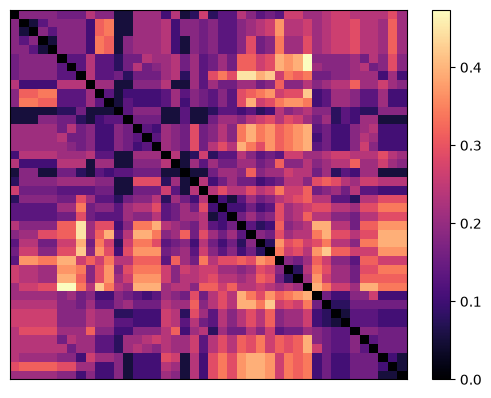

In [15]:
import numpy as np
from ctreex.counterfactuals import volatility_index
from ctreex.plot import metric_heat_map

matrix, leaf_ids, leaf_classes = tree.explainer.leaf_distance_matrix()
_ = metric_heat_map(matrix, leaf_ids, leaf_classes)

The *volatility index* of a leaf grows with the number of leaves of the other
class close to it;
volatile leaves hold applicants whose decision is easy to reverse.
Its distribution for the leaves of each class:

In [16]:
volatility = pd.DataFrame({
    'class': leaf_classes,
    'volatility': [volatility_index(leaf, matrix, leaf_ids, leaf_classes) for leaf in leaf_ids]})
volatility.groupby('class')['volatility'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Bad,26.0,1.13,0.0,1.13,1.13,1.13,1.13,1.13
Good,16.0,2.09,0.0,2.09,2.09,2.09,2.09,2.09
